In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
sys.path.append("../src")

In [4]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import string
import os
import json
from plotters import plot_differentiation_tree, plot_simulated_lineage_tree
from simulator import simulate_multitype_bd_with_diff, save_tree, filter_extant_lineages, load_tree

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

def plot_scatter(ground_truths, inferred):

    x = np.array(ground_truths)
    y = np.array(inferred)

    # Fit regression: y = m x + b
    m, b = np.polyfit(x, y, 1)

    # Correlation
    rho, pval = pearsonr(x, y)

    fig, ax = plt.subplots(figsize=(5, 5))

    # Scatter
    ax.scatter(
        x, y,
        alpha=0.7,
        edgecolors="black",
        linewidths=0.5
    )

    # Regression line
    x_line = np.linspace(x.min(), x.max(), 200)
    y_line = m * x_line + b
    ax.plot(
        x_line,
        y_line,
        linewidth=2,
        label=f"Fit: y = {m:.2f}x + {b:.2f}",
        linestyle="--",
        alpha=0.7,
    )

    # Labels
    ax.set_xlabel("True birth rate", fontsize=12)
    ax.set_ylabel("Inferred birth rate", fontsize=12)

    # Annotation
    ax.text(
        0.05, 0.95,
        f"Pearson ρ = {rho:.3f}\np = {pval:.2e}",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=11,
        bbox=dict(boxstyle="round,pad=0.3")
    )

    # Style
    ax.legend(frameon=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

## Single State

### check likelihood 

In [5]:
T, root = load_tree(f"../data/simulation/single/10/18/T_extant.json")

In [6]:
for u, v, data in T.edges(data=True):
    print(f"{u} -> {v} : {data}")

0 -> 1 : {'start_time': 0.0, 'end_time': 0.18181331444262383, 'length': 0.18181331444262383}
1 -> 2 : {'start_time': 0.18181331444262383, 'end_time': 0.28207302690648467, 'length': 0.10025971246386084}
1 -> 3 : {'start_time': 0.18181331444262383, 'end_time': 3.2706806191153865, 'length': 3.0888673046727626}
2 -> 4 : {'start_time': 0.28207302690648467, 'end_time': 0.4801000391053003, 'length': 0.19802701219881563}
2 -> 5 : {'start_time': 0.28207302690648467, 'end_time': 1.1876923414623222, 'length': 0.9056193145558376}
3 -> 94 : {'start_time': 3.2706806191153865, 'end_time': 3.312022199157045, 'length': 0.04134158004165833}
3 -> 95 : {'start_time': 3.2706806191153865, 'end_time': 3.317289843818289, 'length': 0.04660922470290263}
4 -> 6 : {'start_time': 0.4801000391053003, 'end_time': 0.5466370553787369, 'length': 0.06653701627343656}
4 -> 7 : {'start_time': 0.4801000391053003, 'end_time': 5, 'length': 4.5198999608946995}
5 -> 12 : {'start_time': 1.1876923414623222, 'end_time': 5, 'lengt

In [7]:
cell_lineage_T = nx.DiGraph()

for u, v, data in T.edges(data=True):
    cell_lineage_T.add_edge(u, v, weight=data['length'])

for n, d in T.nodes(data=True):
    if d['event'] == 'sample':
        cell_lineage_T.nodes[n]['state'] = d['type']

In [8]:
from likelihood import add_node_times

In [9]:
cell_lineage_T = add_node_times(cell_lineage_T, reverse=False)

In [10]:
T = cell_lineage_T
rev_T = T.copy()
for n in T.nodes():
    rev_T.nodes[n]['T'] = (T.nodes[n]['T']) / 5

for u, v, data in rev_T.edges(data=True):
    data['weight'] /= 5

In [11]:
from plotters import draw_ultrametric_tree

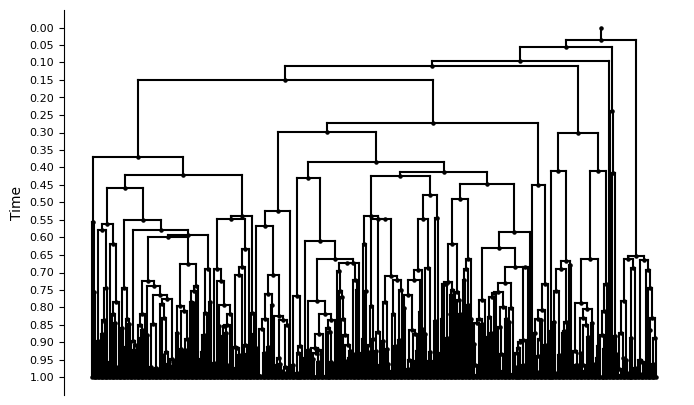

In [12]:
draw_ultrametric_tree(rev_T, root=root, add_labels=False)

In [13]:
rev_T2 = rev_T.copy()

for n in rev_T.nodes():
    rev_T2.nodes[n]['T'] = (1 - rev_T.nodes[n]['T'])

In [14]:
diff_T = nx.DiGraph()

diff_T.add_node("A", diff_time=None)

In [15]:
from likelihood import assign_states_to_internal_nodes

rev_T2 = assign_states_to_internal_nodes(rev_T2, diff_T, correct=True)

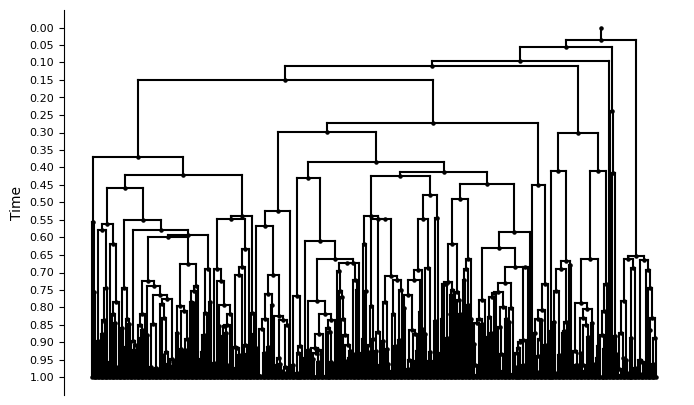

In [16]:
draw_ultrametric_tree(rev_T2, root=root, add_labels=False)

In [17]:
from math import exp, log
import numpy as np

def calculate_log_likelihood(T, birth_rate, death_rate, sampling_rate=1):
    ll = 0.0
    
    ll += len(T.nodes()) * log(birth_rate)

    diff_time = 0
    U = 1 - sampling_rate
    C = (U - 1) / (U - (death_rate / birth_rate))

    for u, v in T.edges():
        u_t = T.nodes[u]['T']
        v_t = T.nodes[v]['T']
        assert u_t > v_t

        flow = exp( -(birth_rate - death_rate) * (u_t - v_t)) * \
                    ( (C - exp( -(birth_rate - death_rate) * (v_t - diff_time))) / 
                      (C - exp( -(birth_rate - death_rate) * (u_t - diff_time))) ) ** 2
        
        assert not np.isnan(flow)

        ll += log(flow)

    return ll    

In [18]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit as sigmoid

MAX_BIRTH = 50.0


def unpack_params(theta):

    k = 0

    birth = MAX_BIRTH * sigmoid(theta[k])
    k += 1

    return birth


def neg_log_likelihood(theta, cell_lineage_T, sampling_rate=1.0):

    birth = unpack_params(theta)
    
    l = calculate_log_likelihood(
        T = cell_lineage_T,
        birth_rate=birth,
        death_rate=1e-30,
        sampling_rate=sampling_rate,
    )

    print(birth,'=>', l)

    return -l


def pack_initial():

    params = []
    params.append(0.0)  # sigmoid(0)=0.5 → birth ≈ halfway to MAX_BIRTH

    return np.array(params)


def find_params(cell_lineage_T):

    theta0 = pack_initial()

    result = minimize(
        neg_log_likelihood,
        theta0,
        args=(cell_lineage_T, 1.0),
        method="L-BFGS-B"
    )

    birth = unpack_params(result.x)

    return birth

In [19]:
find_params(rev_T2)

25.0 => 894.2475464702914
25.000000125 => 894.2475418885142
13.447071068499755 => 1188.7851352717691
13.447071166805724 => 1188.7851344251749
11.338379215268308 => 1195.7218087347976
11.33837930294033 => 1195.7218089692108
11.775056829296082 => 1196.299305805004
11.775056919316256 => 1196.299305805442
11.775884950214206 => 1196.29930778157
11.775885040238762 => 1196.2993077815706


np.float64(11.775884950214206)

In [20]:
import pandas as pd

In [21]:
import pandas as pd

paths = [
    f"data/simulation/single/{i}/{j}"
    for i in range(19)
    for j in range(32)
]

df = pd.DataFrame({"path": paths})
df.to_csv("../data/simulation/single/paths.csv", index=False)

### Check correlation

In [22]:
ground_truths = []
inferred = []

paths = pd.read_csv("../data/simulation/single/paths.csv")["path"]

for path in paths:
    try:

        with open(f"../{path}/../params.json") as f:
            gt_dict = json.load(f)
            true_birth_rate = gt_dict["birth_rates"]["A"]
        
        with open(f"../{path}/birth/inferred_parameters.json") as f:
            inf_dict = json.load(f)
            inferred_birth_rate = inf_dict["birth_rate"]
        
        ground_truths.append(true_birth_rate)
        inferred.append(inferred_birth_rate)
    except Exception as e:
        pass



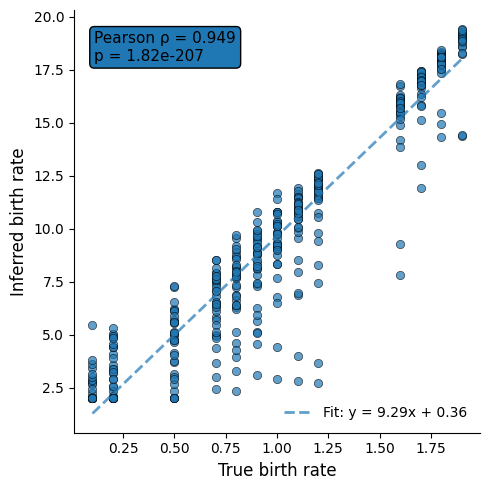

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

x = np.array(ground_truths)
y = np.array(inferred)

# Fit regression: y = m x + b
m, b = np.polyfit(x, y, 1)

# Correlation
rho, pval = pearsonr(x, y)

fig, ax = plt.subplots(figsize=(5, 5))

# Scatter
ax.scatter(
    x, y,
    alpha=0.7,
    edgecolors="black",
    linewidths=0.5
)

# Regression line
x_line = np.linspace(x.min(), x.max(), 200)
y_line = m * x_line + b
ax.plot(
    x_line,
    y_line,
    linewidth=2,
    label=f"Fit: y = {m:.2f}x + {b:.2f}",
    linestyle="--",
    alpha=0.7,
)

# Labels
ax.set_xlabel("True birth rate", fontsize=12)
ax.set_ylabel("Inferred birth rate", fontsize=12)

# Annotation
ax.text(
    0.05, 0.95,
    f"Pearson ρ = {rho:.3f}\np = {pval:.2e}",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=11,
    bbox=dict(boxstyle="round,pad=0.3")
)

# Style
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## Linear

In [24]:
ground_truths_a = []
inferred_a = []
ground_truths_b = []
inferred_b = []



param_ids = [ i for i in range(400)]
param_ids2 = [ i for i in range(324)]
gen_seeds = [ i for i in range(32) ]

for seed in gen_seeds:
    for param_id in param_ids:

        path = f"data/simulation/linear/{param_id}/{seed}"

        try:
        
            with open(f"../{path}/../params.json") as f:
                gt_dict = json.load(f)
                true_birth_rate = gt_dict["birth_rates"]
            
            with open(f"../{path}/birth_given_diff_times/inferred_parameters.json") as f:
                inf_dict = json.load(f)
                inferred_birth_rate = inf_dict["birth_rates"]
            
            ground_truths_a.append(true_birth_rate["A"])
            inferred_a.append(inferred_birth_rate["A"])
        
            ground_truths_b.append(true_birth_rate["B"])
            inferred_b.append(inferred_birth_rate["B"])
        
        except Exception as e:
            pass




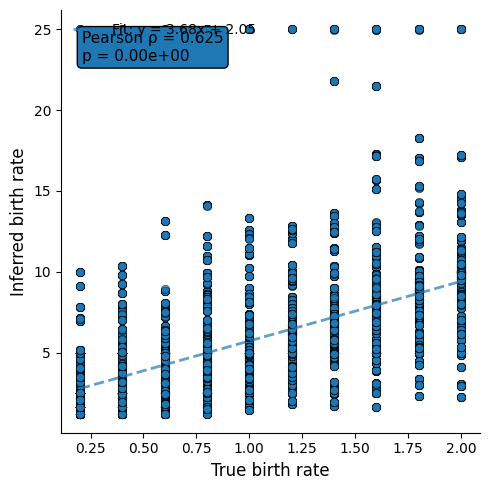

In [25]:
plot_scatter(ground_truths_a, inferred_a)

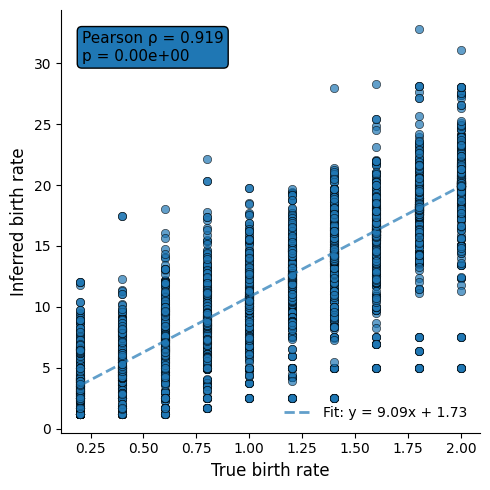

In [26]:
plot_scatter(ground_truths_b, inferred_b)

## Tree

In [27]:
ground_truths_a = []
inferred_a = []
ground_truths_b = []
inferred_b = []
ground_truths_c = []
inferred_c = []



param_ids = [ i for i in range(400)]
param_ids2 = [ i for i in range(324)]
gen_seeds = [ i for i in range(32) ]

for seed in gen_seeds:
    for param_id in param_ids2:

        path = f"data/simulation/tree/{param_id}/{seed}"

        try:
        
            with open(f"../{path}/../params.json") as f:
                gt_dict = json.load(f)
                true_birth_rate = gt_dict["birth_rates"]
            
            with open(f"../{path}/birth_given_diff_times/inferred_parameters.json") as f:
                inf_dict = json.load(f)
                inferred_birth_rate = inf_dict["birth_rates"]
            
            ground_truths_a.append(true_birth_rate["A"])
            inferred_a.append(inferred_birth_rate["A"])
        
            ground_truths_b.append(true_birth_rate["B"])
            inferred_b.append(inferred_birth_rate["B"])

            ground_truths_c.append(true_birth_rate["C"])
            inferred_c.append(inferred_birth_rate["C"])
        
        
        except Exception as e:
            pass




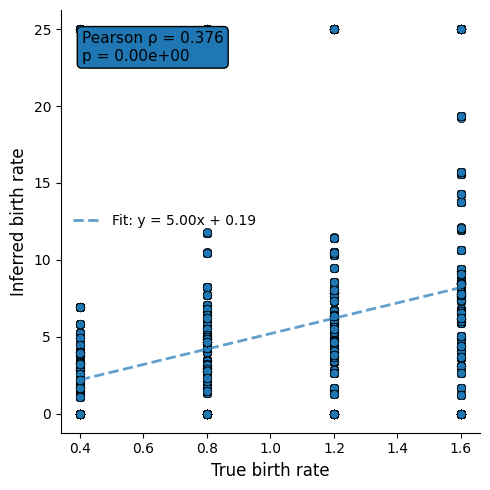

In [28]:
plot_scatter(ground_truths_a, inferred_a)

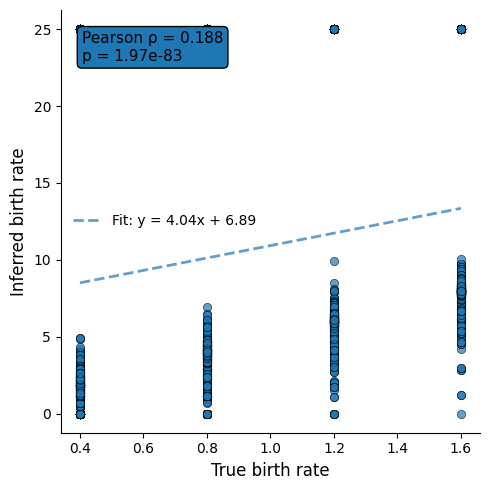

In [29]:
plot_scatter(ground_truths_b, inferred_b)

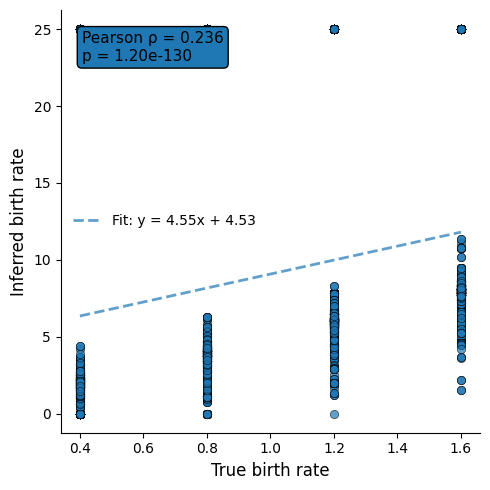

In [30]:
plot_scatter(ground_truths_c, inferred_c)

## Tree 2

In [31]:
ground_truths_a = []
inferred_a = []
ground_truths_b = []
inferred_b = []
ground_truths_c = []
inferred_c = []



param_ids = [ i for i in range(400)]
param_ids2 = [ i for i in range(324)]
gen_seeds = [ i for i in range(32) ]

for seed in gen_seeds:
    for param_id in param_ids2:

        path = f"../data/simulation/tree_comb/{param_id}/{seed}_{(seed+1)%32}"
        source_path = f"../data/simulation/tree/{param_id}"

        try:
        
            with open(f"{source_path}/params.json") as f:
                gt_dict = json.load(f)
                true_birth_rate = gt_dict["birth_rates"]
            
            with open(f"{path}/birth_given_diff_times/inferred_parameters.json") as f:
                inf_dict = json.load(f)
                inferred_birth_rate = inf_dict["birth_rates"]
            
            ground_truths_a.append(true_birth_rate["A"])
            inferred_a.append(inferred_birth_rate["A"])
        
            ground_truths_b.append(true_birth_rate["B"])
            inferred_b.append(inferred_birth_rate["B"])

            ground_truths_c.append(true_birth_rate["C"])
            inferred_c.append(inferred_birth_rate["C"])
        
        
        except Exception as e:
            pass




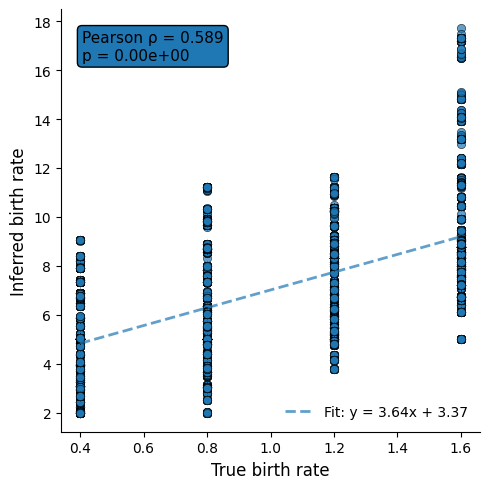

In [32]:
plot_scatter(ground_truths_a, inferred_a)

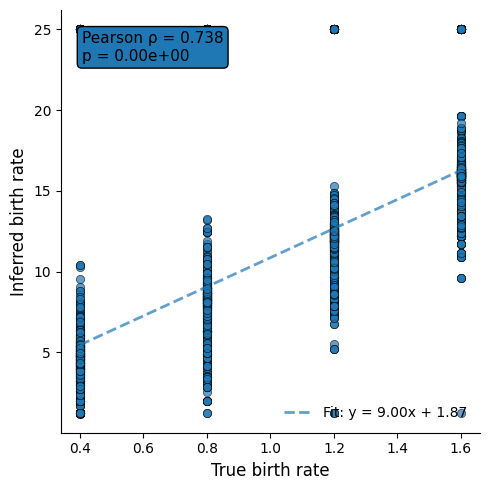

In [33]:
plot_scatter(ground_truths_b, inferred_b)

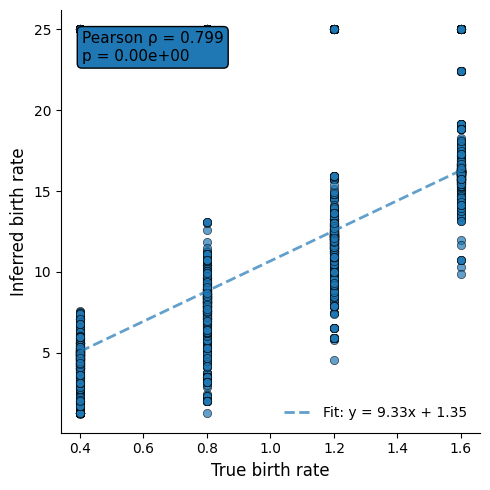

In [34]:
plot_scatter(ground_truths_c, inferred_c)

## Tree 4

In [35]:
ground_truths_a = []
inferred_a = []
ground_truths_b = []
inferred_b = []
ground_truths_c = []
inferred_c = []



param_ids = [ i for i in range(400)]
param_ids2 = [ i for i in range(324)]
gen_seeds = [ i for i in range(32) ]

for seed in gen_seeds:
    for param_id in param_ids2:

        path = f"../data/simulation/tree_comb_4/{param_id}/{seed}_{(seed+1)%32}_{(seed+2)%32}_{(seed+3)%32}"
        source_path = f"../data/simulation/tree/{param_id}"

        try:
        
            with open(f"{source_path}/params.json") as f:
                gt_dict = json.load(f)
                true_birth_rate = gt_dict["birth_rates"]
            
            with open(f"{path}/birth_given_diff_times/inferred_parameters.json") as f:
                inf_dict = json.load(f)
                inferred_birth_rate = inf_dict["birth_rates"]
            
            ground_truths_a.append(true_birth_rate["A"])
            inferred_a.append(inferred_birth_rate["A"])
        
            ground_truths_b.append(true_birth_rate["B"])
            inferred_b.append(inferred_birth_rate["B"])

            ground_truths_c.append(true_birth_rate["C"])
            inferred_c.append(inferred_birth_rate["C"])
        
        
        except Exception as e:
            pass




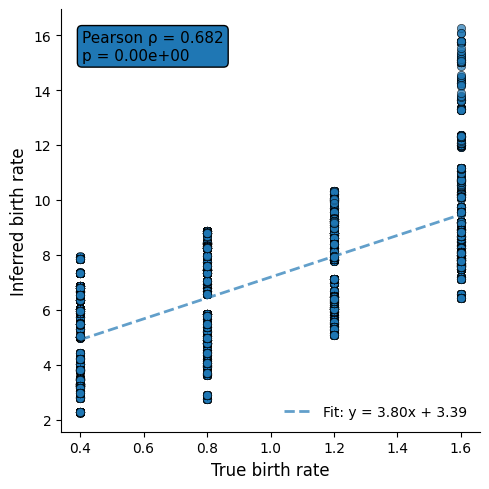

In [36]:
plot_scatter(ground_truths_a, inferred_a)

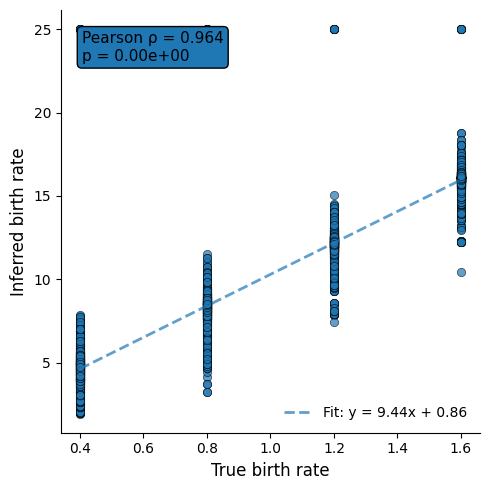

In [37]:
plot_scatter(ground_truths_b, inferred_b)

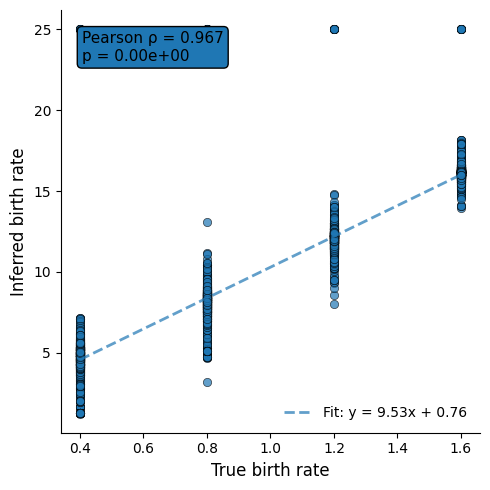

In [38]:
plot_scatter(ground_truths_c, inferred_c)

## 2 stage

In [7]:
ground_truths_a = []
inferred_a = []
ground_truths_b = []
inferred_b = []


param_ids3 = [ i for i in range(432)]
gen_seeds = [ i for i in range(32) ]

for seed in gen_seeds:
    for param_id in param_ids3:

        source_path = f"../data/simulation/2_stage/{param_id}"
        path = f"{source_path}/{seed}"

        try:
        
            with open(f"{source_path}/params.json") as f:
                gt_dict = json.load(f)
                true_birth_rate = gt_dict["birth_rates"]
            
            with open(f"{path}/birth_given_diff_times/inferred_parameters.json") as f:
                inf_dict = json.load(f)
                inferred_birth_rate = inf_dict["birth_rates"]
            
            ground_truths_a.append(true_birth_rate["A"])
            inferred_a.append(inferred_birth_rate["A"])
        
            ground_truths_b.append(true_birth_rate["B"])
            inferred_b.append(inferred_birth_rate["B"])

        
        except Exception as e:
            pass


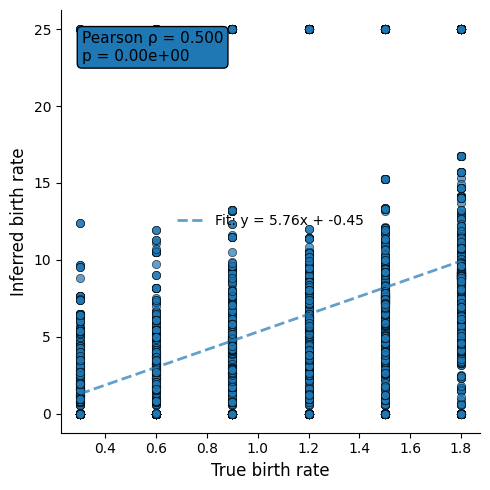

In [8]:
plot_scatter(ground_truths_a, inferred_a)

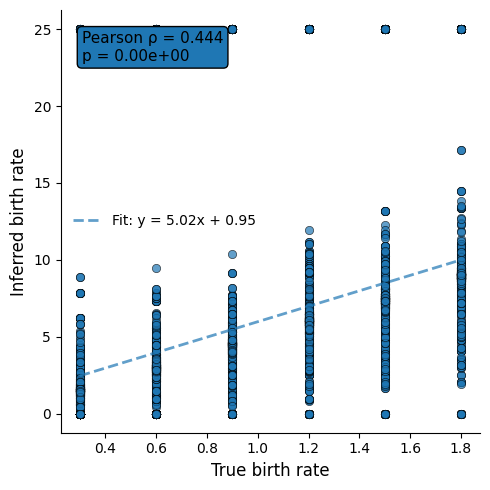

In [9]:
plot_scatter(ground_truths_b, inferred_b)

## LTT

In [17]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

def plot_ltt(
    trees,
    weight_key='length',
    log_scale=True,
):
    
    all_branching_times = []
    
    for T in trees:
        root = [n for n in T.nodes if T.in_degree(n) == 0][0]

        node_times = {}
        def dfs(node, current_time):
            node_times[node] = current_time
            for child in T.successors(node):
                w = T.edges[node, child].get(weight_key, 0.0)
                dfs(child, current_time + w)

        dfs(root, 0.0)

        branching_times = [
            node_times[n]
            for n in T.nodes
            if T.out_degree(n) >= 2
        ]
        all_branching_times.extend(branching_times)

    all_branching_times = np.sort(all_branching_times)

    times = np.insert(all_branching_times, 0, 0.0)
    lineages = np.arange(1, len(times) + 1)

    fig, ax = plt.subplots()

    ax.step(times, lineages, where='post')

    ax.set_xlabel("Time")
    ax.set_ylabel("Number of lineages")

    if log_scale:
        ax.set_yscale("log")

    ax.set_title("Lineage Through Time (LTT)")

    return times, lineages

In [28]:
trees = []
for i in range(576):

    try:
        diff_T, _ = load_tree(f"../data/simulation/tree/{i}/diff_T.json")
        diff_time = diff_T.nodes["A"]['diff_time']
        if diff_time != 2.5: continue
        with open(f"../data/simulation/tree/{i}/params.json") as f:
            params = json.load(f)
            birth_rates = params["birth_rates"]
        
        if not(birth_rates["A"] < birth_rates["B"] and birth_rates["A"] < birth_rates["C"]): continue

        for j in range(32):
            T, root = load_tree(f"../data/simulation/tree/{i}/{j}/T_extant.json")
            trees.append(T)
    except Exception as e:
        pass

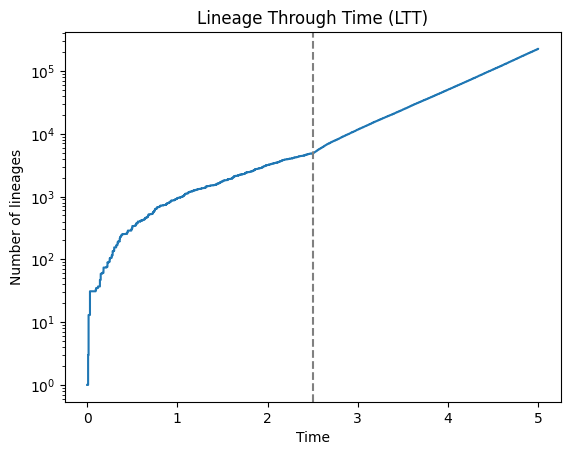

In [29]:
plot_ltt(trees)
plt.axvline(2.5, color='grey', linestyle="--")

plt.show()

In [23]:
trees = []
for i in range(576):

    try:
        diff_T, _ = load_tree(f"../data/simulation/tree/{i}/diff_T.json")
        diff_time = diff_T.nodes["A"]['diff_time']
        if diff_time != 2.5: continue
        with open(f"../data/simulation/tree/{i}/params.json") as f:
            params = json.load(f)
            birth_rates = params["birth_rates"]
        
        if not(birth_rates["A"] > birth_rates["B"] and birth_rates["A"] > birth_rates["C"]): continue

        for j in range(32):
            T, root = load_tree(f"../data/simulation/tree/{i}/{j}/T_extant.json")
            trees.append(T)
    except Exception as e:
        pass

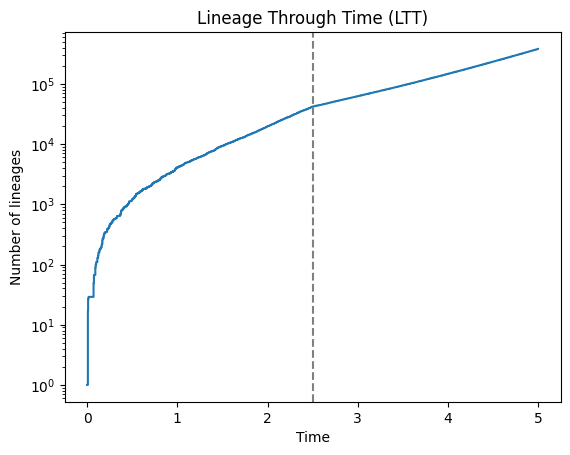

In [27]:
plot_ltt(trees)
plt.axvline(2.5, color='grey', linestyle="--")
plt.show()